## 03 · Embryonic-development signatures

Score the three embryonic modules — **Gast** (gastrulation), **pSom** (posterior somitogenesis), **Crest** (neural crest) — with `score_genes` against the shared **union** control pool, and map each on the manifold. Gate 2 reads the module geography off these embeddings: a Gast/pSom convergence hub diverging into a Gast-leaning and a pSom-leaning arm, with Crest as a terminal readout at the tips.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth       = os.path.join(*(['..'] * 6))
pth_data  = os.path.join(pth, 'data')
pth_in    = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat  = os.path.join(pth_data, 'features', 'biomart')
pth_out   = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb    = os.path.join(pth_out, 'colorbars')
os.makedirs(pth_cb, exist_ok = True)

In [3]:
# load manifold data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); adata

Out[3]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
# build module dictionary (keys = source, vals = human genes)
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src  = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn) : get_feat(fn) for fn in feat_fn}

# score each module against the union control pool
msk_ref = feat_dict['union'].isin(adata.var_names)
g_ref = feat_dict['union'].loc[msk_ref].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.loc[df_src.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata, gene_list = g, score_name = src,
                          ctrl_as_ref = False, gene_pool = g_ref,
                          random_state = 1234)
        print(src, g.size, g_ref.size)

GSE162534 76 224
GSE229103 88 224
rRNAModifications 101 224


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/Gast_signature.pdf


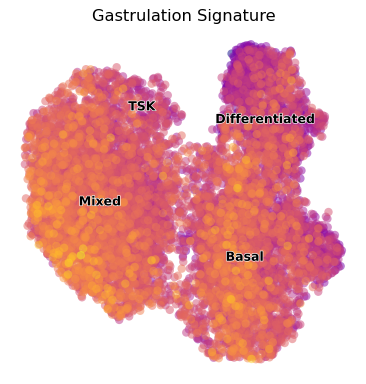

In [5]:
# save gastrulation signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE162534', cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size = 13)
fn = os.path.join(pth_out, 'Gast_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)

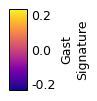

In [6]:
# save gastrulation signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Gast\nSignature')
ticks = np.asarray([-.2, 0, .2])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches = 'tight')

saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/pSom_signature.pdf


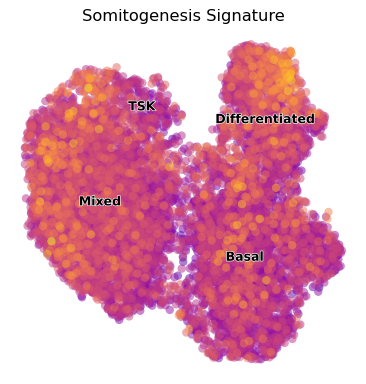

In [7]:
# save somitogenesis signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE229103', cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size = 13)
fn = os.path.join(pth_out, 'pSom_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)

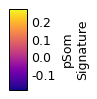

In [8]:
# save somitogenesis signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('pSom\nSignature')
ticks = np.asarray([-.1, 0, .1, .2])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches = 'tight')

saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/Crest_signature.pdf


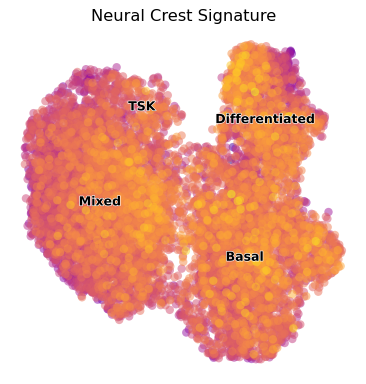

In [9]:
# save neural crest signature figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'rRNAModifications', cmap = 'plasma', alpha = .5,
           size = 180, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size = 13)
fn = os.path.join(pth_out, 'Crest_signature.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)

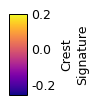

In [10]:
# save neural crest signature colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Crest\nSignature')
ticks = np.asarray([-.2, 0, .2])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches = 'tight')

In [11]:
# save signatures data to h5ad file
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved', os.path.join(pth_in, 'signatures.h5ad'))

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/signatures.h5ad
